In [28]:
from mplsoccer import VerticalPitch
import matplotlib.pyplot as plt
import os
import pandas as pd

In [2]:
events_df = pd.concat(
    [pd.read_parquet(f"../data/{df}") for df in os.listdir("../data") if df.endswith(".parquet")]
)

In [3]:
events_df["start_x"] = events_df["location"].apply(
    lambda loc: loc[0] if isinstance(loc, (list, tuple)) and len(loc) > 0 else None
)

events_df["start_y"] = events_df["location"].apply(
    lambda loc: loc[1] if isinstance(loc, (list, tuple)) and len(loc) > 1 else None
)

<positron-console-cell-3>:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
<positron-console-cell-3>:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`


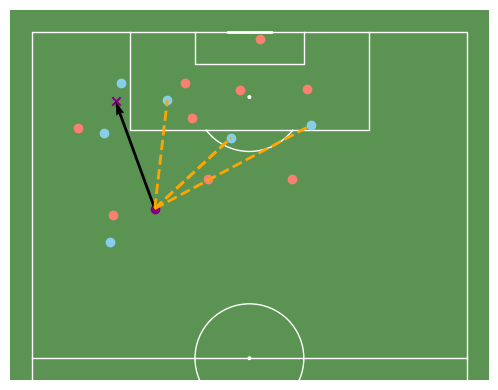

In [41]:
p = VerticalPitch(
    half=True, 
    line_color="white", 
    linewidth=1,
    pitch_color="#5B9452"
)

fig, ax = p.draw(figsize=(6,4))

pitch_data = events_df[(events_df["id"] == "7c674874-ea29-41a2-b69b-24690cd31c81")]

event_type = pitch_data["type"].item().lower()

p.scatter(
        pitch_data["location"].item()[0],
        pitch_data["location"].item()[1],
        color="purple",
        ax=ax
    )

p.scatter(
    pitch_data[f"{event_type}_end_location"].item()[0],
    pitch_data[f"{event_type}_end_location"].item()[1],
    color="purple",
    marker="x",
    ax=ax
)

p.arrows(
    xstart=pitch_data["location"].item()[0], 
    ystart=pitch_data["location"].item()[1], 
    xend=pitch_data[f"{event_type}_end_location"].item()[0],
    yend=pitch_data[f"{event_type}_end_location"].item()[1],
    ax=ax,
    width=2
)

p.lines(
    xstart=pitch_data["location"].item()[0], 
    ystart=pitch_data["location"].item()[1], 
    xend=100.5,
    yend=36.6,
    ax=ax,
    color="orange",
    linewidth=2,
    linestyle="--"
)

p.lines(
    xstart=pitch_data["location"].item()[0], 
    ystart=pitch_data["location"].item()[1], 
    xend=100.5,
    yend=36.6,
    ax=ax,
    color="orange",
    linewidth=2,
    linestyle="--"
)

p.lines(
    xstart=pitch_data["location"].item()[0], 
    ystart=pitch_data["location"].item()[1], 
    xend=107.4,
    yend=24.9,
    ax=ax,
    color="orange",
    linewidth=2,
    linestyle="--"
)

p.lines(
    xstart=pitch_data["location"].item()[0], 
    ystart=pitch_data["location"].item()[1], 
    xend=102.8,
    yend=51.3,
    ax=ax,
    color="orange",
    linewidth=2,
    linestyle="--"
)

for x in pitch_data["freeze_frame"].item():
    if not x["actor"]:
        if x["teammate"]:
            colour = "skyblue"
        else:
            colour = "salmon"
        p.scatter(
            x["location"][0],
            x["location"][1],
            color=colour,
            ax=ax
        )

plt.tight_layout()
plt.savefig("../reports/research-proposal/figures/intro_event_example.png", dpi=600)
plt.show()

In [17]:
pitch_data["freeze_frame"].item()

[{'teammate': True,
  'actor': False,
  'keeper': False,
  'location': [81.31289306222487, 14.44271643928213]},
 {'teammate': False,
  'actor': False,
  'keeper': False,
  'location': [86.29398940439077, 14.931169645839226]},
 {'teammate': True,
  'actor': True,
  'keeper': False,
  'location': [87.5, 22.600000381469727]},
 {'teammate': False,
  'actor': False,
  'keeper': False,
  'location': [92.87667873620913, 32.348936839722434]},
 {'teammate': False,
  'actor': False,
  'keeper': False,
  'location': [92.99852949838431, 47.82198027434041]},
 {'teammate': True,
  'actor': False,
  'keeper': False,
  'location': [100.55754504866472, 36.657802331228844]},
 {'teammate': True,
  'actor': False,
  'keeper': False,
  'location': [101.38960680459894, 13.346473307726946]},
 {'teammate': False,
  'actor': False,
  'keeper': False,
  'location': [102.25216179992486, 8.533908130322438]},
 {'teammate': True,
  'actor': False,
  'keeper': False,
  'location': [102.8000209851572, 51.368471474714